# Kmeans Clustering

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def kMeansClustering(dataSet, numClusters, numIterations):
    dataLength, dataDim = dataSet.shape

    # Step 1: Randomly initialize centroids
    avgPoints = dataSet[np.random.choice(dataLength, numClusters, replace=False), :]

    for iteration in range(numIterations):
        # Step 2: Assign each point to the nearest cluster centroid
        dataSetAssignments = np.zeros((dataLength, 1), dtype=int)

        for i in range(dataLength):
            distances = np.linalg.norm(dataSet[i] - avgPoints, axis=1)
            dataSetAssignments[i] = np.argmin(distances)

        # Step 3: Recompute centroids by averaging points in each cluster
        clusters = [dataSet[dataSetAssignments.flatten() == i] for i in range(numClusters)]
        for i in range(numClusters):
            if len(clusters[i]) > 0:  # Avoid empty clusters
                avgPoints[i] = np.mean(clusters[i], axis=0)

        # Visualization for 2D datasets
        if dataDim == 2:
            colors = ['ro', 'bo', 'go', 'yo', 'mo', 'co', 'ko']
            plt.clf()
            plt.plot(avgPoints[:, 0], avgPoints[:, 1], 'k*', markersize=10)
            for i in range(numClusters):
                if len(clusters[i]) > 0:
                    plt.scatter(clusters[i][:, 0], clusters[i][:, 1], marker='o', label=f'Cluster {i+1}')
            plt.title(f'K-Means Clustering - Iteration {iteration+1}')
            plt.grid(True)
            plt.pause(0.5)

    # Final assignments and cluster centers
    clusterCenters = avgPoints
    dataSetAssignmentsIdx = dataSetAssignments.flatten()

    return clusters, clusterCenters, dataSetAssignmentsIdx




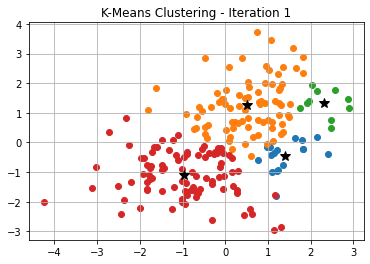

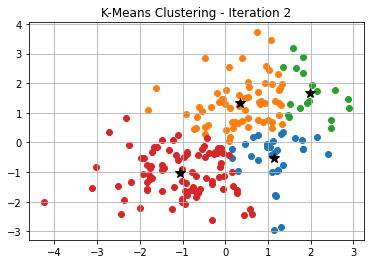

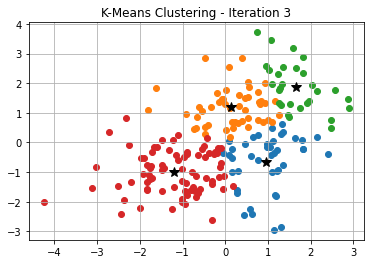

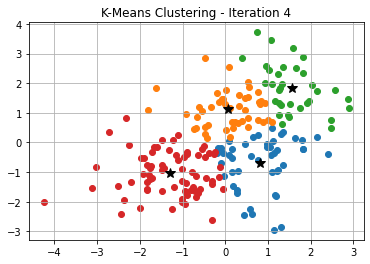

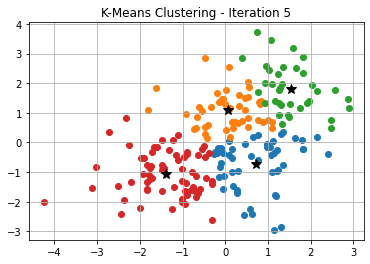

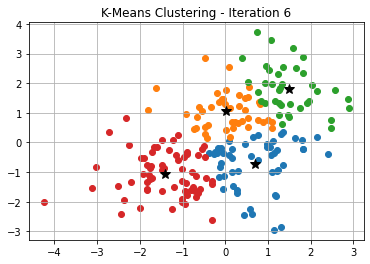

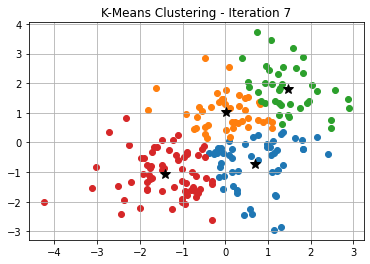

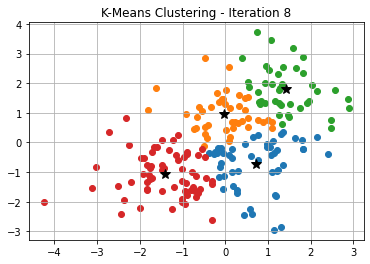

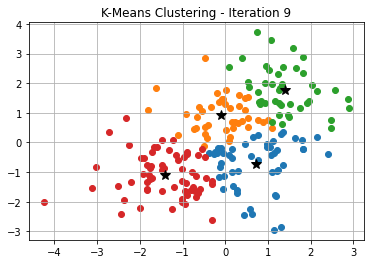

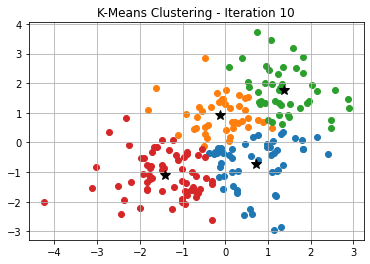

In [3]:
# Example of usage
if __name__ == '__main__':
    # Create example dataset
    np.random.seed(42)
    dataSet = np.vstack([np.random.randn(100, 2) + 1, np.random.randn(100, 2) - 1])

    numClusters = 4
    numIterations = 10
    clusters, clusterCenters, dataSetAssignmentsIdx = kMeansClustering(dataSet, numClusters, numIterations)

    # Show the final result
    plt.show()

# Kmean Clustering on Iris Flower Dataset
![alt text](IrisFlower.jpg "Title")
![alt text](IrisFlowerExpl.png "Title")

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

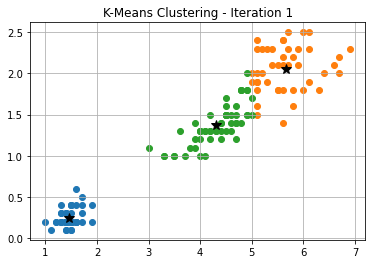

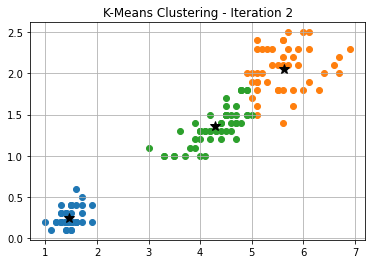

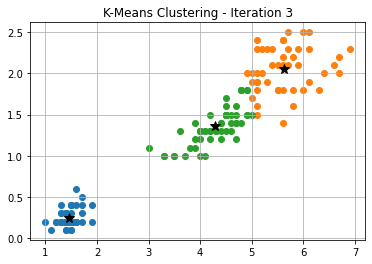

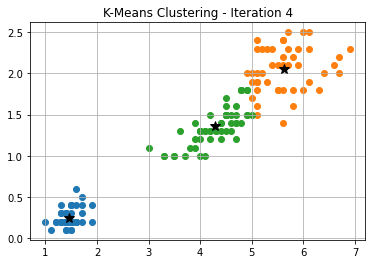

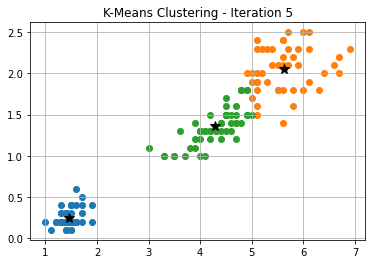

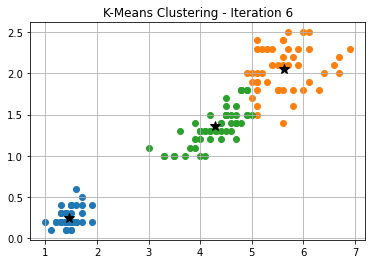

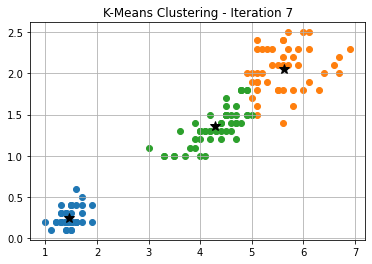

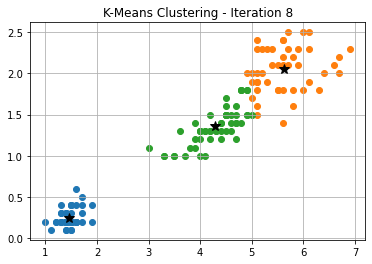

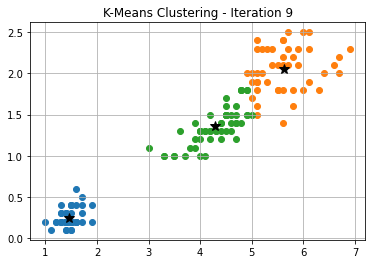

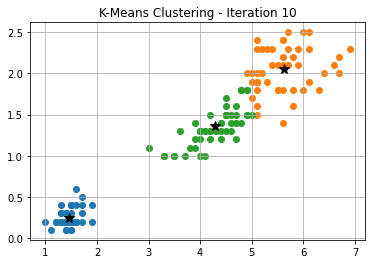

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from skimage import io, img_as_float

# %% EXAMPLE 2: Using Iris Dataset from sklearn

# Load Iris dataset (this will replace the 'iris_dataset' from MATLAB)
iris = datasets.load_iris()
X = iris.data
print(X)

# Select columns 1 to 3 (equivalent to MATLAB's X(:,2:4))
dataSet = X[:, 2:4]

numClusters = 3
numIterations = 10
clusters, clusterCenters, idx = kMeansClustering(dataSet, numClusters, numIterations)

# Show the final result
plt.show()



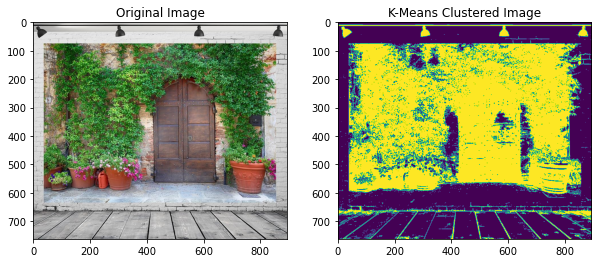

In [13]:

# %% EXAMPLE 3: Image Segmentation using K-Means Clustering
import cv2

# Load image and convert it to double precision (float in Python)
image = img_as_float(io.imread('testimage4.jpg'))  # Replace with your image file path
R = image[:, :, 0].ravel()
G = image[:, :, 1].ravel()
B = image[:, :, 2].ravel()

# Create a dataset from the R, G, B channels
dataSet = np.column_stack([R, G, B])

numClusters = 2
numIterations = 10
clusters, clusterCenters, idx = kMeansClustering(dataSet, numClusters, numIterations)

# Reshape the cluster assignment back into the shape of the original image
m, n, _ = image.shape
idx2D = idx.reshape(m, n)

# Plot the original image and the clustered image
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(idx2D, cmap='viridis')
plt.title("K-Means Clustered Image")
plt.show()